# Adult dataset: EDA

Train set only. To re-run, put `adult.data` and `adult.test` in `data/`.

In [1]:
import matplotlib.pyplot as plt

from preprocessing import FEATURES, load_adult

train, test = load_adult()

## Class balance

In [2]:
rate = train["income"].mean()
print(f"{train['income'].sum():,} of {len(train):,} rows are >50K ({rate:.1%})")
print(f"Always predicting <=50K gets {1 - rate:.1%} accuracy")

7,841 of 32,561 rows are >50K (24.1%)
Always predicting <=50K gets 75.9% accuracy


Any model has to beat 75.9% accuracy.

## Missing values

In [3]:
unknown = train[FEATURES].eq("Unknown")
print(unknown.sum()[lambda s: s > 0].to_string(), "\n")

missing = unknown.any(axis=1)
print(f"Rows with a missing value: {missing.sum():,} ({missing.mean():.1%})")
print(f"Share >50K: {train.loc[missing, 'income'].mean():.1%} with a missing value, "
      f"{train.loc[~missing, 'income'].mean():.1%} without")

workclass         1836
occupation        1843
native-country     583 

Rows with a missing value: 2,399 (7.4%)
Share >50K: 13.9% with a missing value, 24.9% without


Keep these rows, with `Unknown` as a category: they're much less likely to be `>50K`, so dropping them would bias the data.

## Numeric features

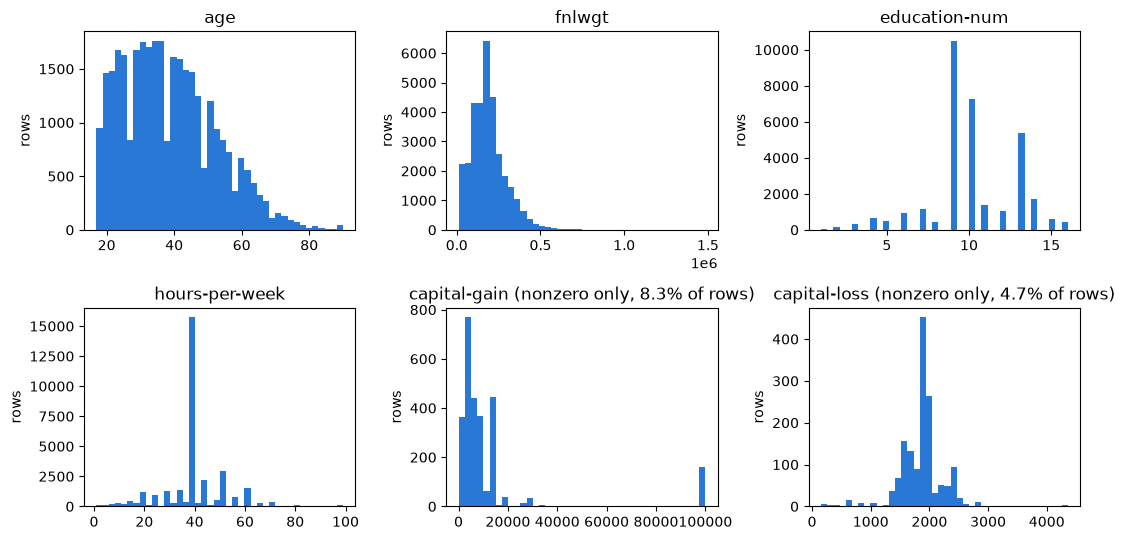

In [4]:
columns = ["age", "fnlwgt", "education-num", "hours-per-week", "capital-gain", "capital-loss"]
fig, axes = plt.subplots(2, 3, figsize=(11, 5.5))
for ax, col in zip(axes.flat, columns):
    values = train[col]
    title = col
    if col.startswith("capital"):
        title = f"{col} (nonzero only, {(values > 0).mean():.1%} of rows)"
        values = values[values > 0]
    ax.hist(values, bins=40, color="#2a78d6")
    ax.set_title(title)
    ax.set_ylabel("rows")
fig.tight_layout()
plt.show()

The capital columns are mostly zero, so `onehot` applies `log1p` to them.